# Deep Learning, Phase 1, Day 4: Project, Neural Network on Breast Cancer Data
**Task:** classify tumours as malignant or benign from 30 measurements, with a PyTorch MLP.

Steps: 1. Data and splits  2. Scaling  3. Model  4. Training with validation  5. Learning curves  6. Test evaluation  7. Baselines  8. How stable are the results?  9. Comparison


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
sns.set_theme(style='whitegrid')
torch.manual_seed(0); np.random.seed(0)

## 1. Data and splits
Breast Cancer data from scikit-learn: 569 patients, 30 features, target `0` = **malignant**, `1` = benign. We use the **same test split as Week 3** (25% test, `random_state=42`) so the results are comparable. From the training part we take another 20% as a **validation set**, which we use to watch the training and to make decisions. The test set stays locked.

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print('Shape:', X.shape, '| classes:', dict(zip(data.target_names, np.bincount(y))))

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)   # same as Week 3
X_tr, X_val, y_tr, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full)
print(f'Train: {len(X_tr)} | Validation: {len(X_val)} | Test: {len(X_test)}')

Shape: (569, 30) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Train: 340 | Validation: 86 | Test: 143


## 2. Scaling
Neural networks train badly when features have very different ranges (for example `area` in the hundreds, `smoothness` below 1). We standardise with `StandardScaler`, **fitted on the training part only**, then applied to validation and test.

In [3]:
scaler = StandardScaler().fit(X_tr)
Xtr_s, Xval_s, Xte_s = scaler.transform(X_tr), scaler.transform(X_val), scaler.transform(X_test)
to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
Xtr, Xval, Xte = to_t(Xtr_s), to_t(Xval_s), to_t(Xte_s)
ytr, yval, yte = (to_t(v).unsqueeze(1) for v in (y_tr, y_val, y_test))
print('Mean of scaled train features (should be about 0):', round(float(Xtr.mean()), 3))

Mean of scaled train features (should be about 0): 0.0


## 3. The model
**30 inputs -> 32 (ReLU) -> 16 (ReLU) -> 1 output (logit)**. Loss: `BCEWithLogitsLoss`. Optimizer: Adam, learning rate 0.001. This is the 1,537-parameter network we counted on Day 1.

In [4]:
def make_model(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(30, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
print(make_model())
print('Parameters:', sum(p.numel() for p in make_model().parameters()))

Sequential(
  (0): Linear(in_features=30, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Parameters: 1537


## 4. Training with a validation set

In [5]:
loss_fn = nn.BCEWithLogitsLoss()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        return loss_fn(logits, y).item(), ((logits > 0).float() == y).float().mean().item()

def train(model, epochs=100, lr=1e-3, batch_size=32, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    hist = {'loss': [], 'acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
        for k, v in zip(hist, (*evaluate(model, Xtr, ytr), *evaluate(model, Xval, yval))): hist[k].append(v)
    return hist

model = make_model(seed=0)
hist = train(model, epochs=100)
print(f"Final: train loss {hist['loss'][-1]:.3f}, train acc {hist['acc'][-1]:.3f} | val loss {hist['val_loss'][-1]:.3f}, val acc {hist['val_acc'][-1]:.3f}")

Final: train loss 0.006, train acc 1.000 | val loss 0.013, val acc 0.988


## 5. Learning curves

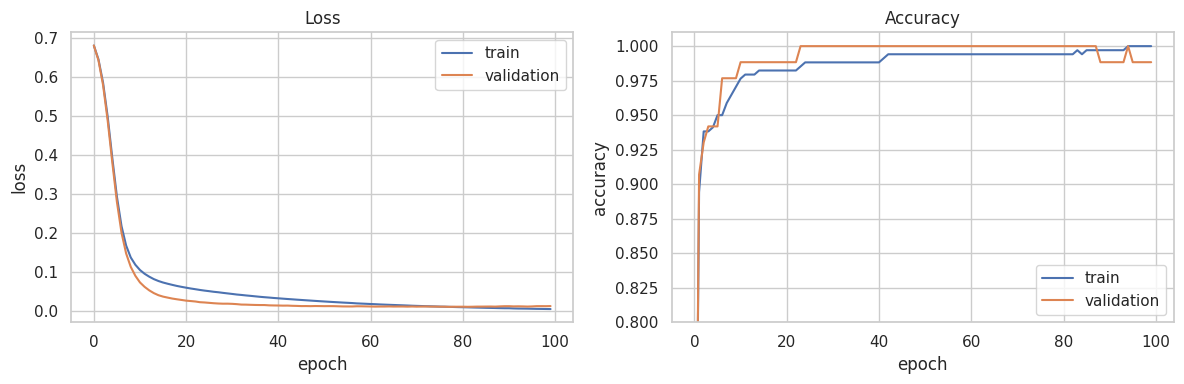

Epoch with the lowest validation loss: 78 | validation loss there: 0.0114 | at the end: 0.0133


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist['loss'], label='train'); ax[0].plot(hist['val_loss'], label='validation'); ax[0].set(xlabel='epoch', ylabel='loss', title='Loss'); ax[0].legend()
ax[1].plot(hist['acc'], label='train'); ax[1].plot(hist['val_acc'], label='validation'); ax[1].set(xlabel='epoch', ylabel='accuracy', title='Accuracy', ylim=(0.8, 1.01)); ax[1].legend()
plt.tight_layout(); plt.show()
best_ep = int(np.argmin(hist['val_loss'])) + 1
print('Epoch with the lowest validation loss:', best_ep, '| validation loss there:', round(min(hist['val_loss']), 4), '| at the end:', round(hist['val_loss'][-1], 4))

## 6. Evaluation on the test set (once)
Class `0` (malignant) is the important one: a missed malignant tumour (false negative) is the costliest mistake, so we report **recall for malignant** as well as accuracy.

accuracy               0.965
malignant recall       0.981
malignant precision    0.929
malignant F1           0.954


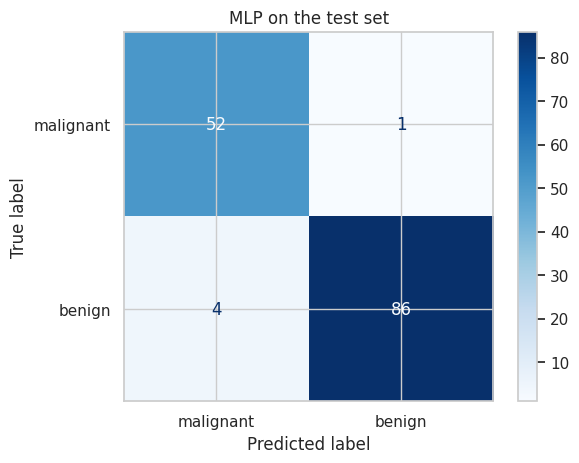

              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        53
      benign       0.99      0.96      0.97        90

    accuracy                           0.97       143
   macro avg       0.96      0.97      0.96       143
weighted avg       0.97      0.97      0.97       143



In [7]:
model.eval()
with torch.no_grad(): pred = (model(Xte) > 0).int().ravel().numpy()
def report(y_true, p):
    return {'accuracy': accuracy_score(y_true, p), 'malignant recall': recall_score(y_true, p, pos_label=0),
            'malignant precision': precision_score(y_true, p, pos_label=0), 'malignant F1': f1_score(y_true, p, pos_label=0)}
print(pd.Series(report(y_test, pred)).round(3).to_string())
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=data.target_names, cmap='Blues'); plt.title('MLP on the test set'); plt.show()
print(classification_report(y_test, pred, target_names=data.target_names))

## 7. Baselines: do we beat the simple models?


In [8]:
baselines = {'Logistic Regression': LogisticRegression(max_iter=2000), 'kNN': KNeighborsClassifier(), 'SVM (rbf)': SVC(random_state=42),
             'Random Forest': RandomForestClassifier(random_state=42)}
rows = {'MLP (PyTorch, seed 0)': report(y_test, pred)}
for name, m in baselines.items():
    rows[name] = report(y_test, m.fit(Xtr_s, y_tr).predict(Xte_s))
comp = pd.DataFrame(rows).T.round(3); comp

,accuracy,malignant recall,malignant precision,malignant F1
"MLP (PyTorch, seed 0)",0.965,0.981,0.929,0.954
Logistic Regression,0.986,0.981,0.981,0.981
kNN,0.965,0.925,0.980,0.951
SVM (rbf),0.965,0.943,0.962,0.952
Random Forest,0.951,0.925,0.942,0.933


## 8. How stable is the neural network?
The test set has only 143 patients, so **one patient is about 0.007 accuracy**. A neural network also depends on its random starting weights. Train it with 5 different seeds and look at the spread:

In [9]:
accs, recs = [], []
for s in range(5):
    m = make_model(seed=s); train(m, epochs=100, seed=s); m.eval()
    with torch.no_grad(): p = (m(Xte) > 0).int().ravel().numpy()
    accs.append(accuracy_score(y_test, p)); recs.append(recall_score(y_test, p, pos_label=0))
print('Test accuracy per seed      :', np.round(accs, 3), f'-> mean {np.mean(accs):.3f} +/- {np.std(accs):.3f}')
print('Malignant recall per seed   :', np.round(recs, 3), f'-> mean {np.mean(recs):.3f} +/- {np.std(recs):.3f}')

Test accuracy per seed      : [0.965 0.965 0.965 0.965 0.965] -> mean 0.965 +/- 0.000
Malignant recall per seed   : [0.981 0.981 0.981 0.981 0.981] -> mean 0.981 +/- 0.000


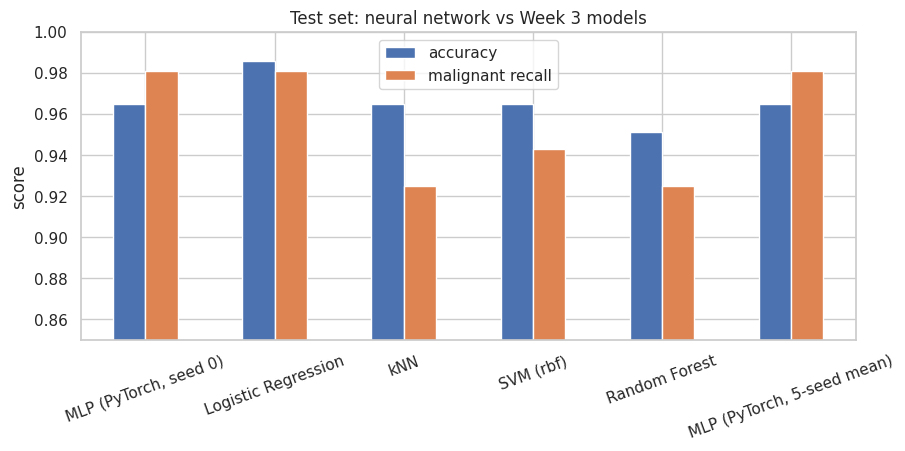

In [10]:
plot_df = comp[['accuracy', 'malignant recall']].copy()
plot_df.loc['MLP (PyTorch, 5-seed mean)'] = [np.mean(accs), np.mean(recs)]
plot_df.plot.bar(figsize=(10, 4), ylim=(0.85, 1.0), title='Test set: neural network vs Week 3 models'); plt.xticks(rotation=20); plt.ylabel('score'); plt.show()

## 9. Save the model
Save the network weights and the scaler, so the model can be used later.

In [11]:
import joblib
torch.save(model.state_dict(), 'breast_cancer_mlp.pt'); joblib.dump(scaler, 'bc_scaler.joblib')
m2 = make_model(); m2.load_state_dict(torch.load('breast_cancer_mlp.pt')); print('Reloaded model test accuracy:', round(evaluate(m2, Xte, yte)[1], 3))

Reloaded model test accuracy: 0.965
